In [7]:
# -*- coding: utf-8 -*-
# General Libraries and Data
import pandas as pd
import seaborn as sns # Update: Use 'sns' as standard alias for seaborn
import numpy as np
import matplotlib.pyplot as plt
import random
import copy
import warnings
# Use mount and files.download/upload commands for Colab environment
from google.colab import drive
from google.colab import files

# Machine Learning Libraries (Scikit-learn)
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV # Combined import for better organization
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Settings
warnings.filterwarnings("ignore")
# Set seed for reproducibility in NumPy and the standard random library
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

In [8]:
# FUNCTIONS

def calculate_df_stats(data_frame, feature_names):
    '''
    Calculates and returns the min, max, and average values
    for the columns of a DataFrame.

    INPUT:
    data_frame (pd.DataFrame): The DataFrame of predictive variables.
    feature_names (list): Names of the columns.

    OUTPUT:
    pd.DataFrame: Table with Min, Max, Avg statistics per variable.
    '''
    stats_data = {
        "Min": [data_frame[col].min() for col in data_frame.columns.values],
        "Max": [data_frame[col].max() for col in data_frame.columns.values],
        "Avg": [data_frame[col].mean() for col in data_frame.columns.values]
    }
    return pd.DataFrame(stats_data, index=feature_names)

def draw_legend_table(axis, data_frame, anchor_pos=(1.05, 0.4, 0.3, 0.5),
                        font_size=8):
    '''
    Creates and places a legend table outside the plot.

    INPUT:
    axis (matplotlib axis): The axis (subfigure) of the plot.
    data_frame (pd.DataFrame): Statistical data (Min, Max, Avg) to display.
    '''
    table_content = []
    # Prepare table content from Min, Max, Avg columns of the DataFrame
    for feature, min_val, max_val, avg_val in zip(
        data_frame.index, data_frame["Min"], data_frame["Max"], data_frame["Avg"]
    ):
        table_content.append([
            feature, f"{min_val:.2f}", f"{max_val:.2f}", f"{avg_val:.2f}"
        ])

    column_labels = ["Predictor", "Min", "Max", "Avg"]

    # Create legend table
    legend_table = axis.table(
        cellText=table_content,
        colLabels=column_labels,
        loc="center left",
        bbox=anchor_pos
    )

    # Set display properties
    legend_table.auto_set_font_size(False)
    legend_table.set_fontsize(font_size)

    # Remove borders for cleaner appearance
    for key, cell in legend_table.get_celld().items():
        cell.set_linewidth(0)
        cell.set_edgecolor("none")

def create_error_bar_plot(axis, data_frame, plot_title: str):
    '''
    Creates an error bar plot for statistical data.

    INPUT:
    axis (matplotlib axis): The axis (subfigure) of the plot.
    data_frame (pd.DataFrame): Statistical data (Min, Max, Avg).
    plot_title (str): Title of the plot.
    '''
    # Calculate error: Distance of Min from Avg and Max from Avg
    y_error_range = [
        data_frame["Avg"] - data_frame["Min"],
        data_frame["Max"] - data_frame["Avg"]
    ]

    # Create errorbar
    axis.errorbar(
        data_frame.index, data_frame["Avg"],
        yerr=y_error_range,
        fmt="o", color="blue", markersize=8, capsize=5
    )
    axis.set_title(plot_title)
    axis.set_xlabel("Indicators")
    axis.set_ylabel("Values")
    axis.set_xticklabels(data_frame.index, rotation=0, ha="right")

    # Add legend table
    draw_legend_table(axis, data_frame)

def plot_confusion_matrix(cf_matrix, class_names, set_label: str, model_name: str): # Added parameters
    '''
    Visualizes the Confusion Matrix using a heatmap.

    INPUT:
    cf_matrix (numpy array): The confusion matrix.
    class_names (list): Names of the classes (e.g., [1, 2] for Healthy, Bankrupt).
    set_label (str): "train" or "test". # Added
    model_name (str): Classifier name. # Added
    '''
    # Calculate metrics and percentages for display
    total_samples = np.sum(cf_matrix)
    group_counts = [f"{value:0.0f}" for value in cf_matrix.flatten()]
    group_percentages = [f"{value:.2%}" for value in cf_matrix.flatten() / total_samples]

    labels_text = [f"{count}\n({percent})" for count, percent in zip(group_counts, group_percentages)]
    labels_reshaped = np.asarray(labels_text).reshape(2, 2)

    # Create heatmap
    ax = sns.heatmap(cf_matrix, annot=labels_reshaped, fmt="", cmap="Blues")

    # Updated title to include model name and set label
    ax.set_title(f"Πίνακας Σύγχυσης ({model_name} - {set_label.capitalize()} Set)\n")
    ax.set_xlabel("\nΠροβλεπόμενη Κατηγορία")
    ax.set_ylabel("Πραγματική Κατηγορία")

    # Set axis labels
    ax.xaxis.set_ticklabels(class_names)
    ax.yaxis.set_ticklabels(class_names)

    plt.show()

from sklearn.metrics import balanced_accuracy_score # Import the new metric

def evaluate_and_report(y_actual, y_predicted, set_label: str, model_name: str, is_balanced: bool, X_train, y_train):
    '''
    Calculates evaluation metrics, displays the Confusion Matrix, and
    returns the results in dictionary format.

    INPUT:
    y_actual: Actual response values.
    y_predicted: Predicted response values.
    set_label (str): "train" or "test".
    model_name (str): Classifier name.
    is_balanced (bool): True if the train set is balanced.
    X_train: Training features (needed for sample count).
    y_train: Training target (needed for non-healthy count).

    OUTPUT:
    dict: Dictionary with all required metrics and information.
    '''
    # Confusion Matrix - Pass model_name and set_label
    conf_matrix = confusion_matrix(y_actual, y_predicted)
    plot_confusion_matrix(conf_matrix, ["Healthy (1)", "Bankrupt (2)"], set_label, model_name)

    # Calculate Metrics (pos_label=2 refers to the bankrupt class)
    acc = accuracy_score(y_actual, y_predicted)
    balanced_acc = balanced_accuracy_score(y_actual, y_predicted) # Calculate Balanced Accuracy
    prec = precision_score(y_actual, y_predicted, pos_label=2)
    rec = recall_score(y_actual, y_predicted, pos_label=2)
    f1 = f1_score(y_actual, y_predicted, pos_label=2)
    ra_score = roc_auc_score(y_actual, y_predicted)

    # Print results
    print(f"Accuracy: {acc:.2f}")
    print(f"Balanced Accuracy: {balanced_acc:.2f}") # Print Balanced Accuracy
    print(f"Precision: {prec:.2f}")
    print(f"Recall (Sensitivity): {rec:.2f}")
    print(f"F1-score: {f1:.2f}")
    print(f"ROC-AUC: {ra_score:.2f}")

    # Get counts for reporting
    unique_train, counts_train = np.unique(y_train.values, return_counts=True)

    # Record results in the dictionary
    results_dict = {
        "Classifier Name": model_name,
        "Training or test set": set_label,
        "Balanced or unbalanced train set": "Balanced" if is_balanced else "Unbalanced", # Added new requirement
        "Number of training samples": len(X_train),
        "Number of non-healthy companies in training sample": counts_train[1],
        "True negatives TN": conf_matrix[0][0], # Class 1 (Healthy)
        "True positive TP": conf_matrix[1][1],  # Class 2 (Bankrupt)
        "False negatives FN": conf_matrix[0][1], # Prediction 2, Actual 1
        "False positives FP": conf_matrix[1][0], # Prediction 1, Actual 2
        "Accuracy": acc, # Also include Accuracy in the dictionary
        "Balanced Accuracy": balanced_acc, # Add Balanced Accuracy to the dictionary
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "ROC-AUC": ra_score
    }
    return results_dict

def train_and_evaluate_model(model_name: str, model_instance, X_train, y_train, X_test, y_test, is_train_balanced, param_grid=None):
    '''
    Performs optimization with GridSearchCV, trains the optimal classifier,
    and evaluates performance on train and test sets.

    INPUT:
    model_name (str): Classifier name.
    model_instance: Model class instance (e.g., KNeighborsClassifier()).
    X_train: Training features.
    y_train: Training target.
    X_test: Test features.
    y_test: Test target.
    is_train_balanced (bool): True if the training set is balanced.
    param_grid (dict): Dictionary with parameters for GridSearchCV.

    OUTPUT:
    list: List of two result dictionaries (train set and test set).
    '''
    # Use GridSearchCV to find optimal parameters
    gs_search = GridSearchCV(model_instance, param_grid if param_grid else {}, cv=3) # Use default cv=3
    gs_search.fit(X_train, y_train)

    # Predictions with the best classifier
    train_predictions = gs_search.predict(X_train)
    test_predictions = gs_search.predict(X_test)

    # Calculate and record results (Train set)
    train_results = evaluate_and_report(
        y_train, train_predictions, "train", model_name, is_train_balanced, X_train, y_train
    )
    # Calculate and record results (Test set)
    test_results = evaluate_and_report(
        y_test, test_predictions, "test", model_name, is_train_balanced, X_train, y_train
    )

    # Print Best Parameters
    best_params = gs_search.best_params_
    print(f"\nBest Parameters for {model_name}: {best_params}\n" + "-"*50)

    return [train_results, test_results]

In [9]:
# Display the DataFrame with the average performance on the test set
# print("DataFrame with average performance on Test Set:")
# display(average_test_performance_sorted)

# If you want to see all test set results from all folds:
# print("\nDataFrame with all Test Set results (all folds):")
# display(final_test_df)

# If you want to see all train set results from all folds:
# print("\nDataFrame with all Train Set results (all folds):")
# display(final_train_df)

In [10]:
# Access the dataset
print("Connecting to Google Drive...")
drive.mount('/content/drive')
# Define path (user needs to change this)
LOCATION = "/content/drive/My Drive/Classification Project/"
FILE_NAME = "Dataset2Use_Assignment1.xlsx"

# Load data into DataFrame
data_set = pd.read_excel(LOCATION + FILE_NAME)

# Rename columns for easier use
new_column_names = {}
# Continuous indicators A-H (columns 0-7) -> x1 to x8
for i in range(8):
    new_column_names[data_set.columns.values[i]] = f"x{i + 1}"
# Binary indicators I-K (columns 8-10) -> binary1 to binary3
for i, col_name in enumerate(data_set.columns.values[8:11]):
    new_column_names[col_name] = f"binary{i + 1}"

# Status column (Y) and Year (year)
new_column_names[data_set.columns.values[-2]] = "Y"
new_column_names[data_set.columns.values[-1]] = "year"

data_set.rename(columns=new_column_names, inplace=True)

# Έλεγχος για ελλείπεις εγγραφές (NaNs)
print("\n--- Έλεγχος Ελλειπουσών Τιμών (NaNs) ---")
nan_counts = data_set.isnull().sum()
if nan_counts.sum() == 0:
    print("Δεν βρέθηκαν ελλείπουσες τιμές (NaNs).")
else:
    print("Βρέθηκαν οι ακόλουθες ελλείπουσες τιμές ανά στήλη:")
    print(nan_counts[nan_counts > 0])
print("-" * 50)

Connecting to Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- Έλεγχος Ελλειπουσών Τιμών (NaNs) ---
Δεν βρέθηκαν ελλείπουσες τιμές (NaNs).
--------------------------------------------------


In [11]:
%pip install xlsxwriter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 4.4 MB/s eta 0:00:00


In [12]:
import pandas as pd
import os

# Καθορισμός της διαδρομής όπου βρίσκονται τα αρχεία CSV
# Σε περιβάλλον Colab, αυτά βρίσκονται συνήθως στον τρέχοντα φάκελο '/content/'
csv_folder_path = '/content/'

# Λίστα για τα αρχεία CSV που θέλουμε να μετατρέψουμε
csv_files_to_convert = []

# Βρίσκουμε όλα τα αρχεία CSV στον φάκελο που ακολουθούν το συγκεκριμένο μοτίβο ονόματος
for file_name in os.listdir(csv_folder_path):
    if file_name.startswith('balancedDataOutcomes') and file_name.endswith('.csv'):
        csv_files_to_convert.append(file_name)

if not csv_files_to_convert:
    print(f"Δεν βρέθηκαν αρχεία CSV με το μοτίβο 'balancedDataOutcomes_*.csv' στον φάκελο '{csv_folder_path}'.")
else:
    print(f"Βρέθηκαν {len(csv_files_to_convert)} αρχεία CSV προς μετατροπή:")
    for csv_file_name in csv_files_to_convert:
        print(f"- {csv_file_name}")

        # Ορισμός του ονόματος του αρχείου Excel (αντικαθιστούμε το .csv με .xlsx)
        excel_file_name = csv_file_name.replace('.csv', '.xlsx')
        csv_full_path = os.path.join(csv_folder_path, csv_file_name)
        excel_full_path = os.path.join(csv_folder_path, excel_file_name)

        try:
            # Διάβασμα του αρχείου CSV σε DataFrame
            df_from_csv = pd.read_csv(csv_full_path)

            # Αποθήκευση του DataFrame σε αρχείο Excel
            df_from_csv.to_excel(excel_full_path, index=False, engine='xlsxwriter')

            print(f"Μετατροπή: '{csv_file_name}' -> '{excel_file_name}' ολοκληρώθηκε.")

        except FileNotFoundError:
            print(f"Σφάλμα: Το αρχείο '{csv_full_path}' δεν βρέθηκε κατά τη μετατροπή.")
        except Exception as e:
            print(f"Παρουσιάστηκε σφάλμα κατά τη μετατροπή του '{csv_file_name}': {e}")

    print("\nΟλοκληρώθηκε η μετατροπή όλων των βρεθέντων αρχείων CSV σε Excel.")

# Μπορείτε να κατεβάσετε τα αρχεία Excel αν βρίσκεστε σε περιβάλλον Colab
# from google.colab import files
# for file_name in [f.replace('.csv', '.xlsx') for f in csv_files_to_convert]:
#   if os.path.exists(os.path.join(csv_folder_path, file_name)):
#     files.download(os.path.join(csv_folder_path, file_name))

Δεν βρέθηκαν αρχεία CSV με το μοτίβο 'balancedDataOutcomes_*.csv' στον φάκελο '/content/'.


<Figure size 1000x600 with 0 Axes>

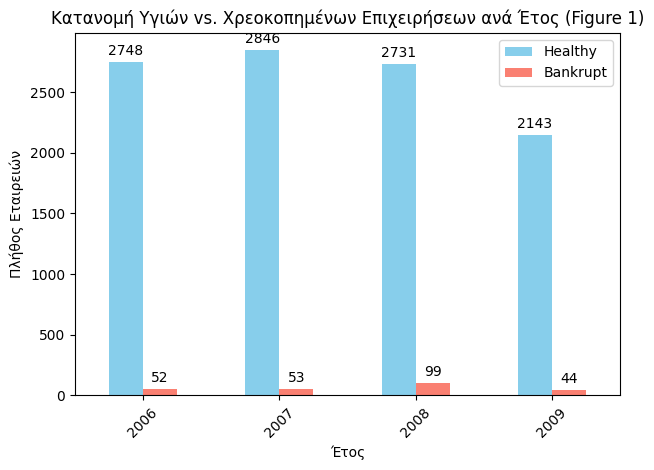

In [13]:
# Figure 1 - Number of Healthy (Y=1) and Bankrupt (Y=2) per Year
unique_years = data_set['year'].unique()
status_counts_per_year = {
    "Healthy": [data_set[data_set["year"] == yr]["Y"].value_counts().get(1, 0) for yr in unique_years],
    "Bankrupt": [data_set[data_set["year"] == yr]["Y"].value_counts().get(2, 0) for yr in unique_years]
}

status_df = pd.DataFrame(status_counts_per_year, index=unique_years)

plt.figure(figsize=(10, 6))
# Changed colors for Healthy and Bankrupt bars
bar_plot_fig = status_df.plot.bar(rot=45, color=['skyblue', 'salmon'])

# Display values above each bar
for bar_container in bar_plot_fig.containers:
    bar_plot_fig.bar_label(bar_container, fmt='%d', label_type='edge', padding=3)

bar_plot_fig.set_title("Κατανομή Υγιών vs. Χρεοκοπημένων Επιχειρήσεων ανά Έτος (Figure 1)")
bar_plot_fig.set_xlabel("Έτος")
bar_plot_fig.set_ylabel("Πλήθος Εταιρειών")
plt.tight_layout()
plt.savefig(LOCATION + "Figure_1_new.png", dpi=300)
plt.show()

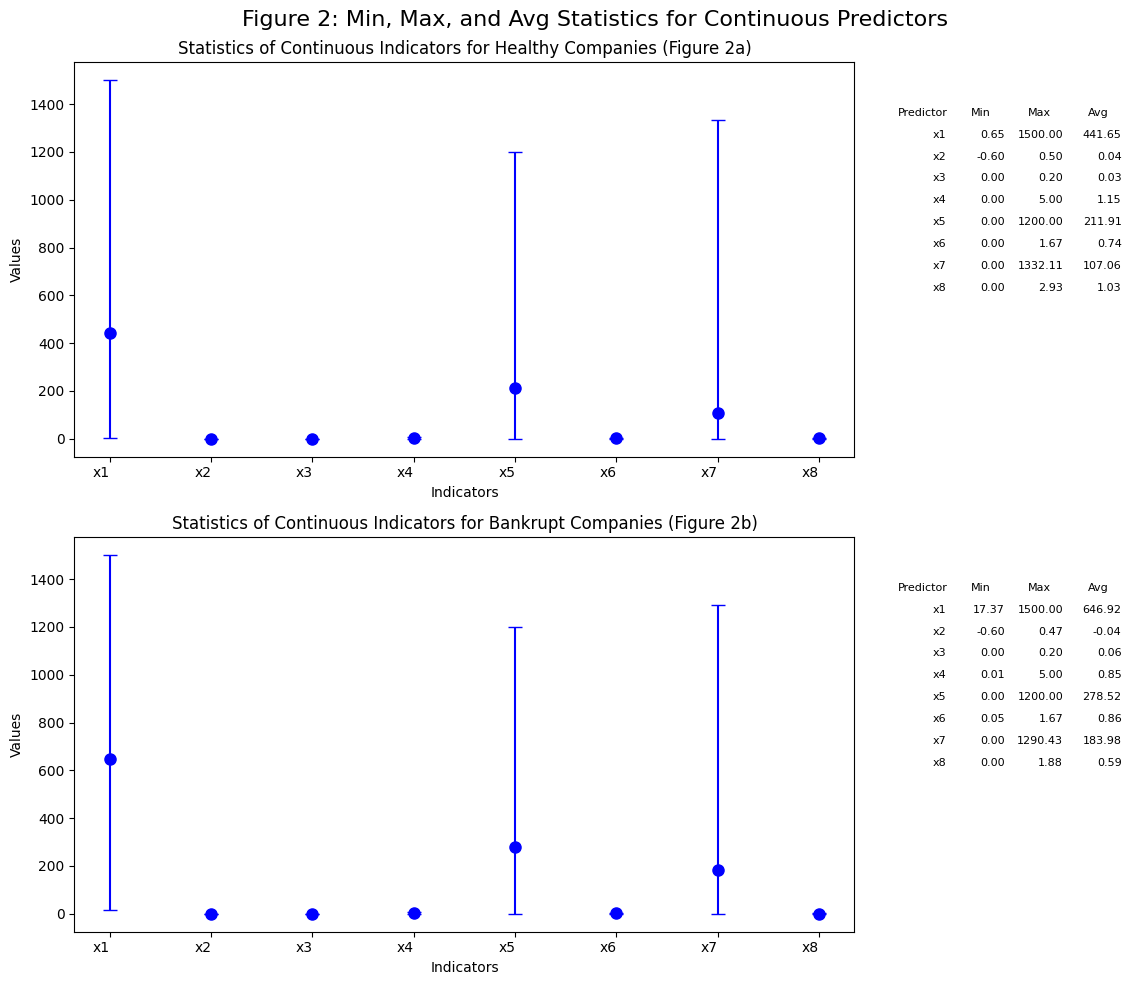

In [14]:
# Figure 2 - Min, Max, Avg for continuous indicators (Separation Healthy/Bankrupt)
healthy_companies_df = data_set[data_set["Y"] == 1].copy()
bankrupt_companies_df = data_set[data_set["Y"] == 2].copy()

# Continuous indicators (x1 to x8)
continuous_predictors = [f"x{i+1}" for i in range(8)]
healthy_stats = calculate_df_stats(healthy_companies_df[continuous_predictors], continuous_predictors)
bankrupt_stats = calculate_df_stats(bankrupt_companies_df[continuous_predictors], continuous_predictors)

# Visualize Figure 2
fig_stats, (axis1, axis2) = plt.subplots(nrows=2, figsize=(12, 10))

# Changed color and enlarged table size
create_error_bar_plot(axis1, healthy_stats, "Statistics of Continuous Indicators for Healthy Companies (Figure 2a)")
create_error_bar_plot(axis2, bankrupt_stats, "Statistics of Continuous Indicators for Bankrupt Companies (Figure 2b)")


# Add overall title to the figure
fig_stats.suptitle("Figure 2: Min, Max, and Avg Statistics for Continuous Predictors", fontsize=16)

# Add a small margin between subplots
plt.subplots_adjust(hspace=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Normalization (MinMaxScaler)

# Separate predictors and response
continuous_predictors = [f"x{i+1}" for i in range(8)]
input_continuous = data_set[continuous_predictors]
input_binary = data_set[[f"binary{i+1}" for i in range(3)]]
y_target = data_set["Y"]

# Apply MinMaxScaler to continuous variables
minmax_scaler = MinMaxScaler()
scaled_continuous_array = minmax_scaler.fit_transform(input_continuous)
scaled_continuous_df = pd.DataFrame(
    scaled_continuous_array,
    columns=input_continuous.columns
)

# Final input set (scaled continuous + binary)
X_features = pd.concat([scaled_continuous_df, input_binary.reset_index(drop=True)], axis=1)

In [16]:
# Stratified K-Fold (4 Folds) and Model Training/Evaluation Loop

# shuffle=False to have folds based on order, maintaining dataset structure
stratified_folds = StratifiedKFold(n_splits=4, shuffle=False)
stratified_folds.get_n_splits(X_features, y_target)

# Initial list to collect results
all_train_results = []
all_test_results = []

# Loop execution for each Fold
for fold_idx, (train_idx, test_idx) in enumerate(stratified_folds.split(X_features, y_target)):

    print("\n" + "=" * 70)
    print(f"                                   FOLD {fold_idx}")
    print("=" * 70)

    # Split Train/Test data for the current fold
    X_train, X_test = X_features.iloc[train_idx].copy(), X_features.iloc[test_idx].copy()
    y_train, y_test = y_target.iloc[train_idx].copy(), y_target.iloc[test_idx].copy()

    # Distribution before balancing
    unique_train, counts_train = np.unique(y_train.values, return_counts=True)
    unique_test, counts_test = np.unique(y_test.values, return_counts=True)

    print(f"Αρχικό Πλήθος Train/Test: {len(X_train)} / {len(X_test)}")
    print(f"Αρχική Κατανομή Train: Υγιείς={counts_train[0]}, Χρεοκοπημένες={counts_train[1]}")
    print(f"Αρχική Κατανομή Test: Υγιείς={counts_test[0]}, Χρεοκοπημένες={counts_test[1]}")

    # Flag for Train Set status
    is_train_balanced = False

    # Balance Train Set (Undersampling)
    # Required ratio: Healthy (Y=1) <= 3 * Bankrupt (Y=2)
    if counts_train[0] > 3 * counts_train[1]:
        print("\n*** Εφαρμογή Undersampling για εξισορρόπηση (3:1) ***")
        is_train_balanced = True

        bankrupt_indices = y_train[y_train == 2].index.tolist()
        healthy_indices = y_train[y_train == 1].index.tolist()

        # Calculate how many healthy companies to keep (3 * number of bankrupt)
        target_healthy_count = 3 * counts_train[1]

        # Select a random subset of healthy companies
        # Using np.random.choice with replace=False (selection without replacement)
        selected_healthy_indices = np.random.choice(
            healthy_indices,
            size=target_healthy_count,
            replace=False
        ).tolist()

        # The new train set indices are the bankrupt + selected healthy
        new_train_indices = bankrupt_indices + selected_healthy_indices

        # Indices of healthy companies removed from the train set
        # IMPORTANT: These samples will NOT be added to the test set, as requested by the assignment
        # discarded_healthy_indices = [i for i in healthy_indices if i not in selected_healthy_indices]
        # (No further action needed for the test set)

        # Create new, balanced train set
        X_train = X_features.loc[new_train_indices].copy()
        y_train = y_target.loc[new_train_indices].copy()

    # Print new distribution
    unique_train, counts_train = np.unique(y_train.values, return_counts=True)
    ratio_df = pd.DataFrame({
        "Train": [counts_train[0], counts_train[1]],
        "Test": [counts_test[0], counts_test[1]]
    }, index=["Healthy (1)", "Bankrupt (2)"])

    print("\nΝΕΕΣ ΚΑΤΑΝΟΜΕΣ (μετά την πιθανή εξισορρόπηση):")
    display(ratio_df)
    print("-" * 50)


    # Train and Evaluate Classifiers

    # K-Nearest Neighbors (K-nn)
    knn_results = train_and_evaluate_model(
        "K-nn", KNeighborsClassifier(), X_train, y_train, X_test, y_test, is_train_balanced,
        {"n_neighbors": range(1, 50)}
    )
    # Initialize results DataFrames
    fold_train_results_df = pd.DataFrame([knn_results[0]])
    fold_test_results_df = pd.DataFrame([knn_results[1]])

    # Gaussian Naive Bayes (Gaussian NB)
    nb_results = train_and_evaluate_model("Gaussian NB", GaussianNB(), X_train, y_train, X_test, y_test, is_train_balanced)
    fold_train_results_df = pd.concat([fold_train_results_df, pd.DataFrame([nb_results[0]])], ignore_index=True)
    fold_test_results_df = pd.concat([fold_test_results_df, pd.DataFrame([nb_results[1]])], ignore_index=True)

    # Support Vector Machine (SVM) - Extended grid
    svm_results = train_and_evaluate_model(
        "SVM", SVC(random_state=RANDOM_SEED), X_train, y_train, X_test, y_test, is_train_balanced,
        {'C': [0.01, 0.1, 1, 10, 100], # C extended
         'gamma': ['scale', 'auto', 0.01, 0.1, 1, 10], # gamma extended
         'kernel': ['linear', 'rbf', 'poly']} # poly added
    )
    fold_train_results_df = pd.concat([fold_train_results_df, pd.DataFrame([svm_results[0]])], ignore_index=True)
    fold_test_results_df = pd.concat([fold_test_results_df, pd.DataFrame([svm_results[1]])], ignore_index=True)

    # Linear Discriminant Analysis (LDA)
    lda_results = train_and_evaluate_model(
        "LDA", LinearDiscriminantAnalysis(), X_train, y_train, X_test, y_test, is_train_balanced,
        {"solver": ["svd", "lsqr", "eigen"]}
    )
    fold_train_results_df = pd.concat([fold_train_results_df, pd.DataFrame([lda_results[0]])], ignore_index=True)
    fold_test_results_df = pd.concat([fold_test_results_df, pd.DataFrame([lda_results[1]])], ignore_index=True)

    # Logistic Regression
    lg_results = train_and_evaluate_model(
        "Logistic Regression", LogisticRegression(random_state=RANDOM_SEED, max_iter=10000), X_train, y_train, X_test, y_test, is_train_balanced,
        {"C":np.logspace(-4,4,9), "penalty":["l2"]} # C range extended
    )
    fold_train_results_df = pd.concat([fold_train_results_df, pd.DataFrame([lg_results[0]])], ignore_index=True)
    fold_test_results_df = pd.concat([fold_test_results_df, pd.DataFrame([lg_results[1]])], ignore_index=True)

    # Decision Trees
    dt_results = train_and_evaluate_model(
        "Decision Trees", DecisionTreeClassifier(random_state=RANDOM_SEED), X_train, y_train, X_test, y_test, is_train_balanced,
        {'max_features': ['sqrt', 'log2', None],
         'max_depth' : [3, 5, 7, 9, 11], # max_depth extended
         'criterion' :['gini', 'entropy']}
    )
    fold_train_results_df = pd.concat([fold_train_results_df, pd.DataFrame([dt_results[0]])], ignore_index=True)
    fold_test_results_df = pd.concat([fold_test_results_df, pd.DataFrame([dt_results[1]])], ignore_index=True)

    # Random Forest - Extended grid
    rf_results = train_and_evaluate_model(
        "Random Forest", RandomForestClassifier(random_state=RANDOM_SEED), X_train, y_train, X_test, y_test, is_train_balanced,
        {'n_estimators': [50, 100, 200, 300], # Number of estimators extended
         'max_features': ['sqrt', 'log2', None], # None added
         'max_depth' : [6, 8, 10, 12]} # max_depth extended
    )
    fold_train_results_df = pd.concat([fold_train_results_df, pd.DataFrame([rf_results[0]])], ignore_index=True)
    fold_test_results_df = pd.concat([fold_test_results_df, pd.DataFrame([rf_results[1]])], ignore_index=True)

    # PassiveAggressiveClassifier
    from sklearn.linear_model import PassiveAggressiveClassifier
    pa_results = train_and_evaluate_model(
        "PassiveAggressiveClassifier", PassiveAggressiveClassifier(random_state=RANDOM_SEED, max_iter=1000, tol=1e-3), X_train, y_train, X_test, y_test, is_train_balanced,
        {'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
         'fit_intercept': [True, False],
         'loss': ['hinge', 'squared_hinge']}
    )
    fold_train_results_df = pd.concat([fold_train_results_df, pd.DataFrame([pa_results[0]])], ignore_index=True)
    fold_test_results_df = pd.concat([fold_test_results_df, pd.DataFrame([pa_results[1]])], ignore_index=True)


    all_train_results.append(fold_train_results_df)
    all_test_results.append(fold_test_results_df)

    # Save and Download Results for the current Fold
    train_file_name = f"balancedDataOutcomes_Train_Fold_{fold_idx}.csv"
    test_file_name = f"balancedDataOutcomes_Test_Fold_{fold_idx}.csv"

    fold_train_results_df.to_csv(train_file_name, index=False)
    fold_test_results_df.to_csv(test_file_name, index=False)

    print(f"\nΑποτελέσματα Fold {fold_idx} αποθηκεύτηκαν σε CSV.")
    # files.download(train_file_name)
    # files.download(test_file_name)

# Final saving (optional)
# Concatenate DataFrames from all folds
final_train_df = pd.concat(all_train_results, ignore_index=True)
final_test_df = pd.concat(all_test_results, ignore_index=True)

# final_train_df.to_csv("FINAL_ALL_TRAIN_RESULTS.csv", index=False)
# final_test_df.to_csv("FINAL_ALL_TEST_RESULTS.csv", index=False)

Output hidden; open in https://colab.research.google.com to view.